In [1]:
# import
import os, sys, pickle
import numpy as np
import pandas as pd
import scipy as sp
from tqdm import tqdm

# import plotting libraries
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 8})
plt.rcParams["svg.fonttype"] = "none"
import seaborn as sns
from nilearn import datasets
from nilearn import plotting

sys.path.extend([r'/home/lindenmp/research_projects/snaplab_tools'])
sys.path.extend([r'/home/lindenmp/research_projects/nctpy/src'])

from src.ints import compute_timescales, get_task_events, compute_autocorrelation_with_hrf
from src.plotting import plot_autocorrelation_analysis

In [2]:
from nilearn.plotting import plot_design_matrix

import warnings
warnings.simplefilter('ignore', UserWarning)

## Setup

In [3]:
# directory where data is stored
indir = '/home/lindenmp/research_projects/intrinsic_neural_timescales/data'
which_data = 'HCP-YA'
# which_data = 'HCP-D'
# which_data = 'RBC-PNC'
# which_data = 'RBC-HBN'
# which_data = 'RBC-NKI'
outdir = '/home/lindenmp/research_projects/intrinsic_neural_timescales/results/{0}'.format(which_data.replace('_', ''))

if not os.path.exists(outdir):
    os.makedirs(outdir)

atlas = 'Schaefer4007'
if atlas == 'Schaefer4007':
    n_parcels = 400
    n_nodes = 400
elif atlas == 'Schaefer2007':
    n_parcels = 200
    n_nodes = 200
elif atlas == 'Schaefer1007':
    n_parcels = 100
    n_nodes = 100
    
if which_data == 'HCP-YA':
    tr = 0.720
    rest_scans = ['rfMRI_REST1_LR', 'rfMRI_REST2_LR', 'rfMRI_REST1_RL', 'rfMRI_REST2_RL']
    tasks = ['tfMRI_WM_LR', 'tfMRI_EMOTION_LR', 'tfMRI_GAMBLING_LR', 'tfMRI_LANGUAGE_LR', 'tfMRI_RELATIONAL_LR', 'tfMRI_SOCIAL_LR',
             'tfMRI_WM_RL', 'tfMRI_EMOTION_RL', 'tfMRI_GAMBLING_RL', 'tfMRI_LANGUAGE_RL', 'tfMRI_RELATIONAL_RL', 'tfMRI_SOCIAL_RL']
elif which_data == 'HCP-D':
    tr = 0.800
    # tasks = ['tfMRI_CARIT_PA', 'tfMRI_EMOTION_PA', 'tfMRI_GUESSING_PA']
    tasks = ['tfMRI_CARIT_PA',]
elif which_data == 'RBC-PNC':
    tr = 3
    tasks = ['frac2back',]
elif which_data == 'RBC-HBN':
    tr = 0.800
    # tr_rutgers = 0.800
    # tr_staten = 1.45
elif which_data == 'RBC-NKI':
    tr = 0.800

In [4]:
subject_ids = np.loadtxt(os.path.join(indir, '{0}_{1}_subjids.txt'.format(which_data, atlas)), dtype=str)
n_subs = len(subject_ids)
print(n_subs)

947


## Resting-state timescales

In [5]:
rest_timescales = dict()
for i, which_scan in enumerate(rest_scans):
    print(which_scan)
    rest_ts = np.load(os.path.join(indir, '{0}_{1}_rsts-{2}.npy'.format(which_data, atlas, which_scan.replace('_', ''))))
    print(rest_ts.shape)

    rest_timescales[which_scan] = compute_timescales(rest_ts, return_mean=False).T
    print(rest_timescales[which_scan].shape)

rfMRI_REST1_LR
(1200, 400, 947)
947 400


100%|██████████| 947/947 [01:28<00:00, 10.65it/s]


(947, 400)
rfMRI_REST2_LR
(1200, 400, 947)
947 400


100%|██████████| 947/947 [01:28<00:00, 10.70it/s]


(947, 400)
rfMRI_REST1_RL
(1200, 400, 947)
947 400


100%|██████████| 947/947 [01:27<00:00, 10.82it/s]


(947, 400)
rfMRI_REST2_RL
(1200, 400, 947)
947 400


100%|██████████| 947/947 [01:28<00:00, 10.73it/s]

(947, 400)


## Task-based timescales and constrasts

tfMRI_WM_LR


  0%|          | 0/947 [00:00<?, ?it/s]

['0bk' '2bk']


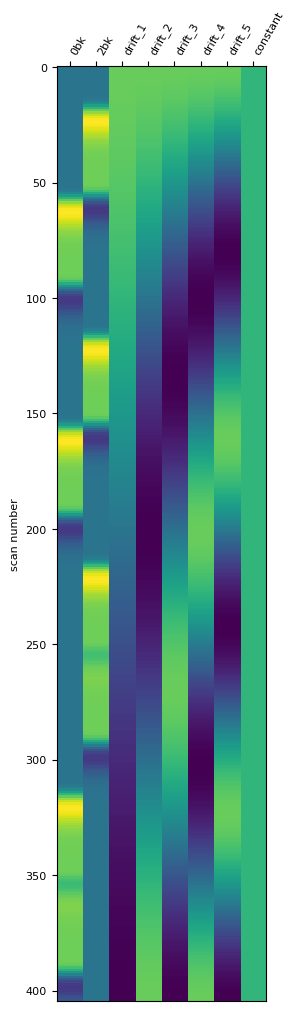

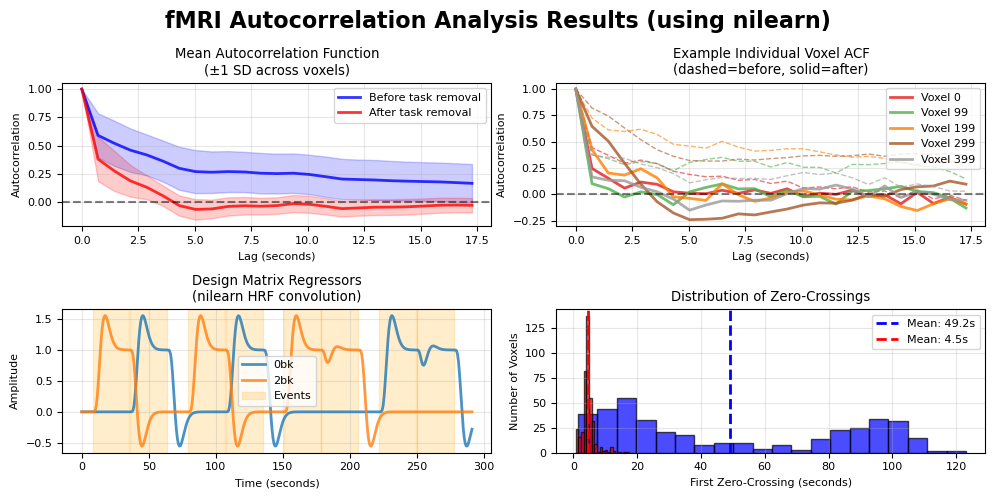

100%|██████████| 947/947 [01:08<00:00, 13.77it/s]


0
tfMRI_EMOTION_LR


  0%|          | 0/947 [00:00<?, ?it/s]

['fear' 'neut']


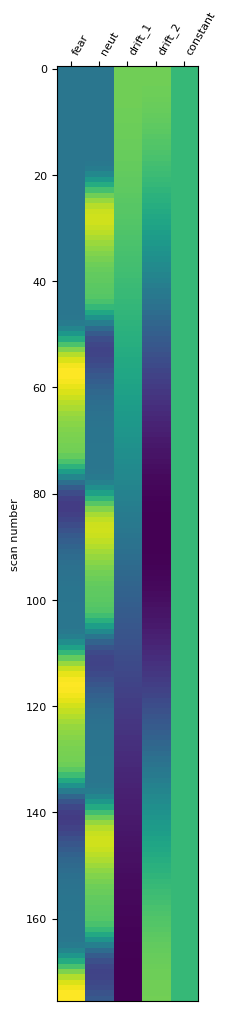

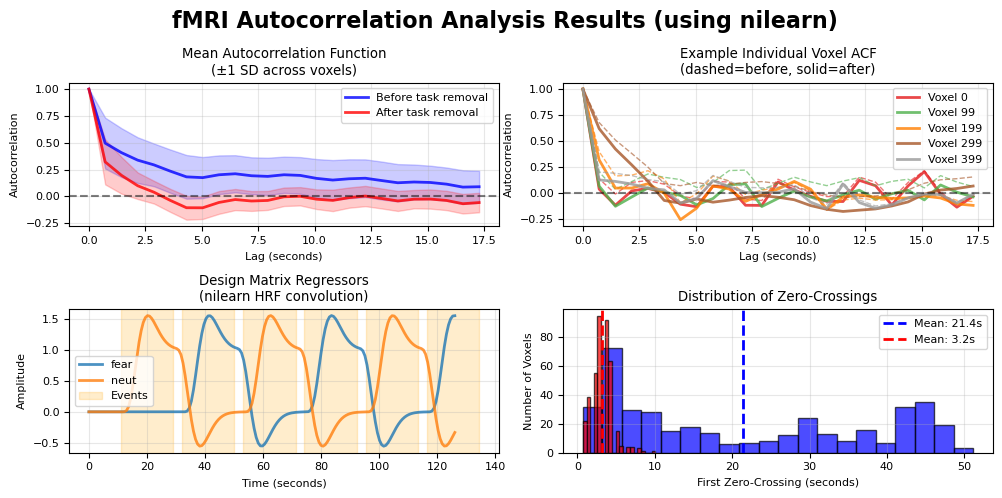

100%|██████████| 947/947 [00:37<00:00, 25.55it/s]


0
tfMRI_GAMBLING_LR


  0%|          | 0/947 [00:00<?, ?it/s]

['loss' 'win']


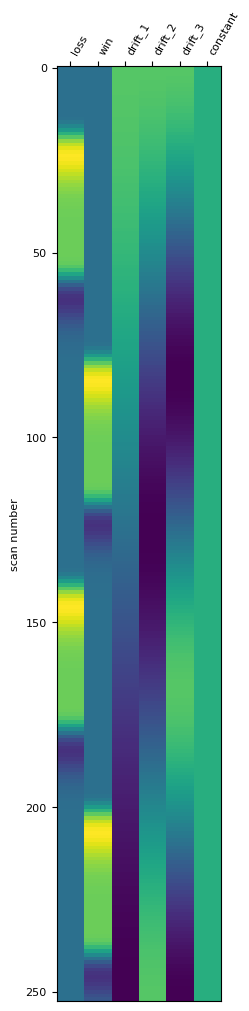

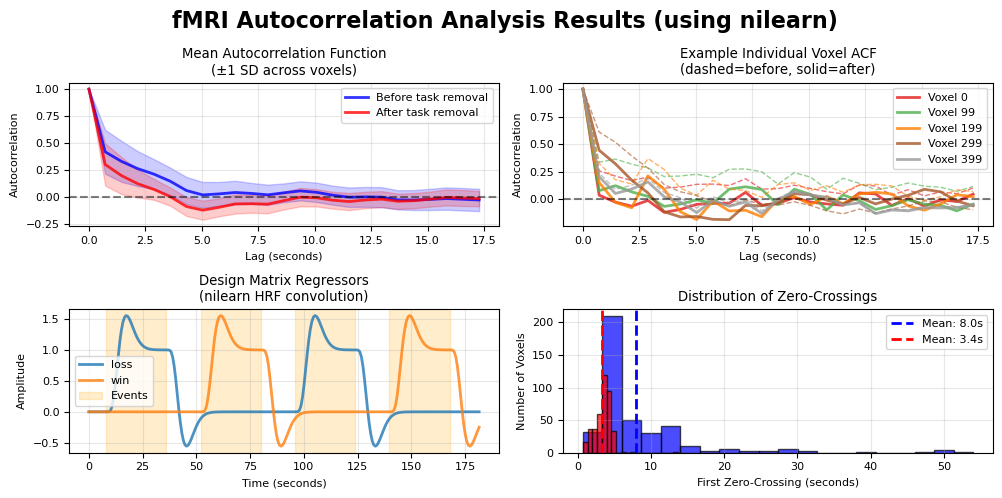

100%|██████████| 947/947 [00:44<00:00, 21.26it/s]


0
tfMRI_LANGUAGE_LR


  0%|          | 0/947 [00:00<?, ?it/s]

['math' 'story']


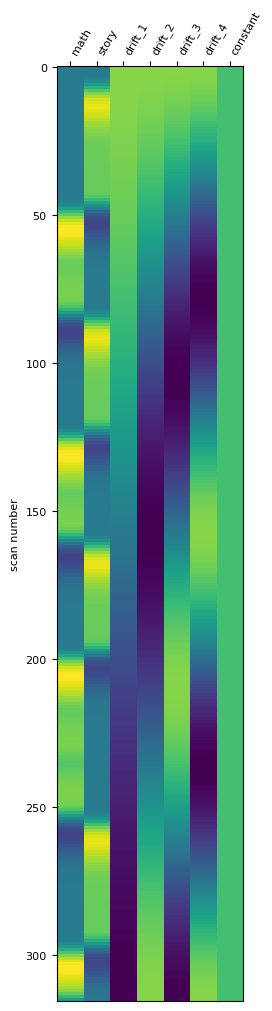

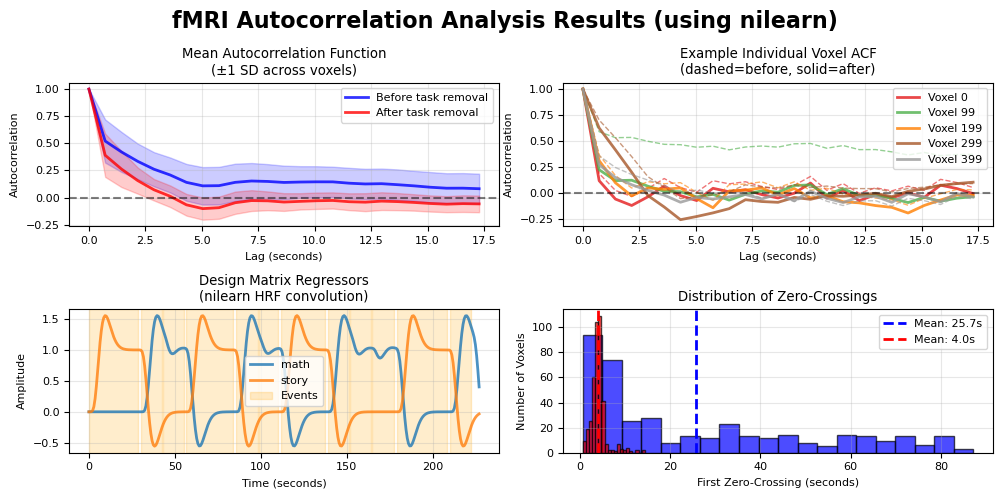

100%|██████████| 947/947 [00:54<00:00, 17.25it/s]


0
tfMRI_RELATIONAL_LR


  0%|          | 0/947 [00:00<?, ?it/s]

['match' 'relation']


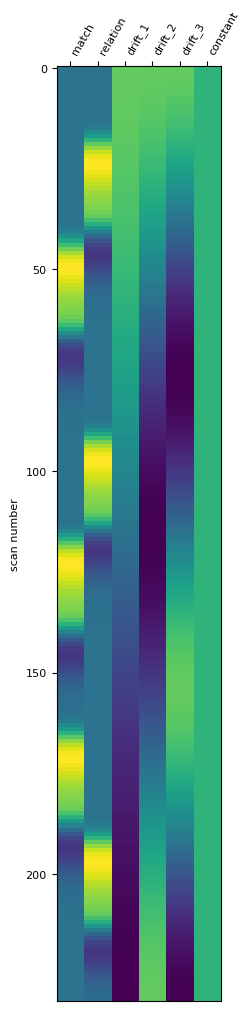

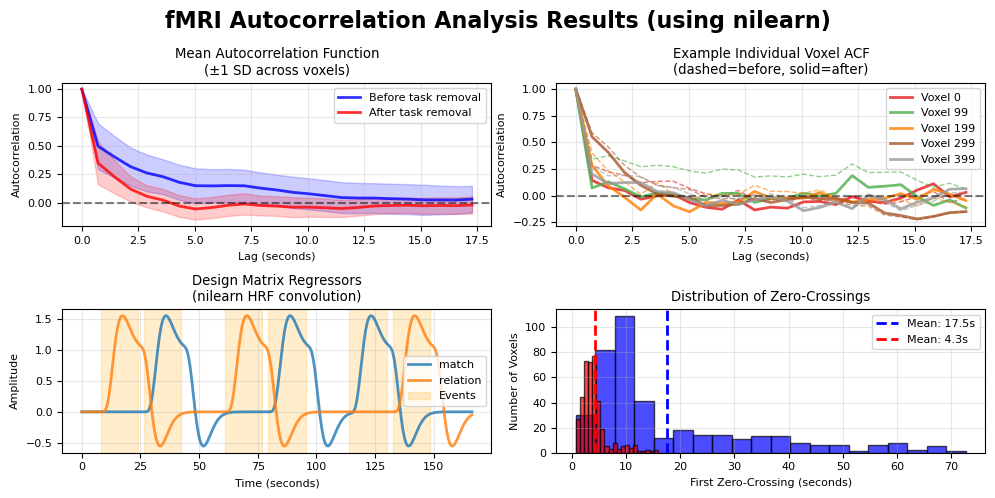

100%|██████████| 947/947 [00:41<00:00, 22.81it/s]


0
tfMRI_SOCIAL_LR


  0%|          | 0/947 [00:00<?, ?it/s]

['mental' 'rnd']


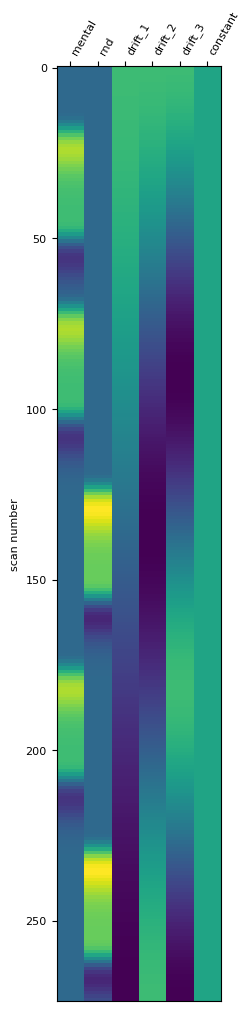

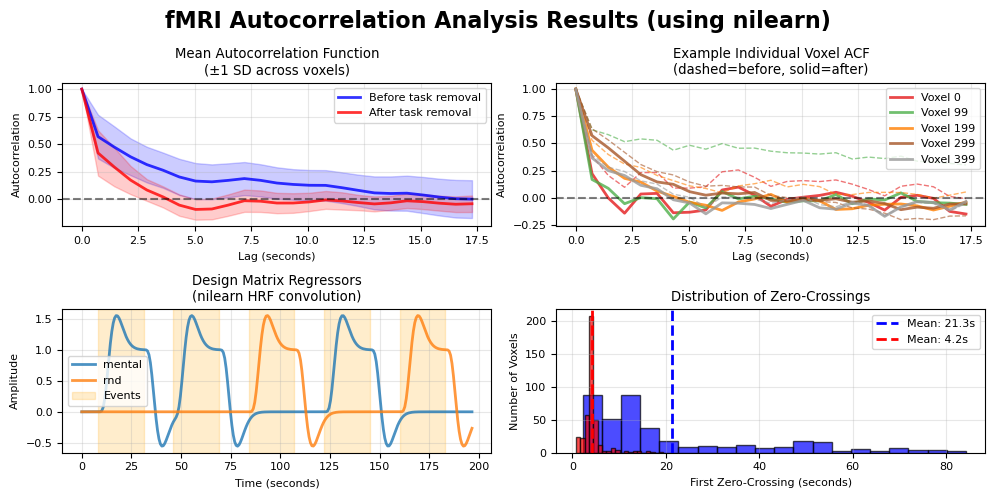

100%|██████████| 947/947 [00:45<00:00, 20.66it/s]


0
tfMRI_WM_RL


  0%|          | 0/947 [00:00<?, ?it/s]

['0bk' '2bk']


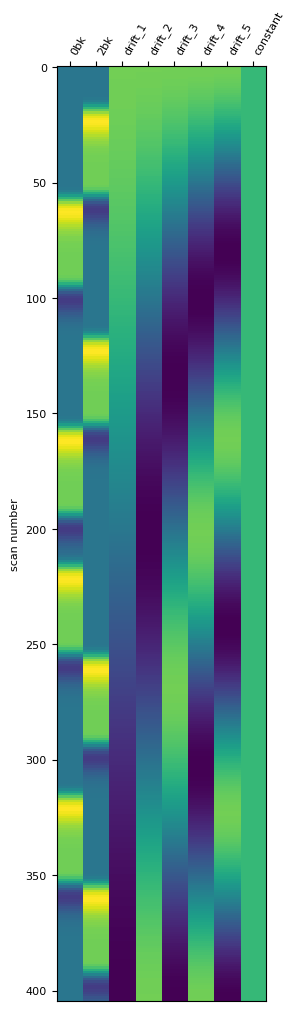

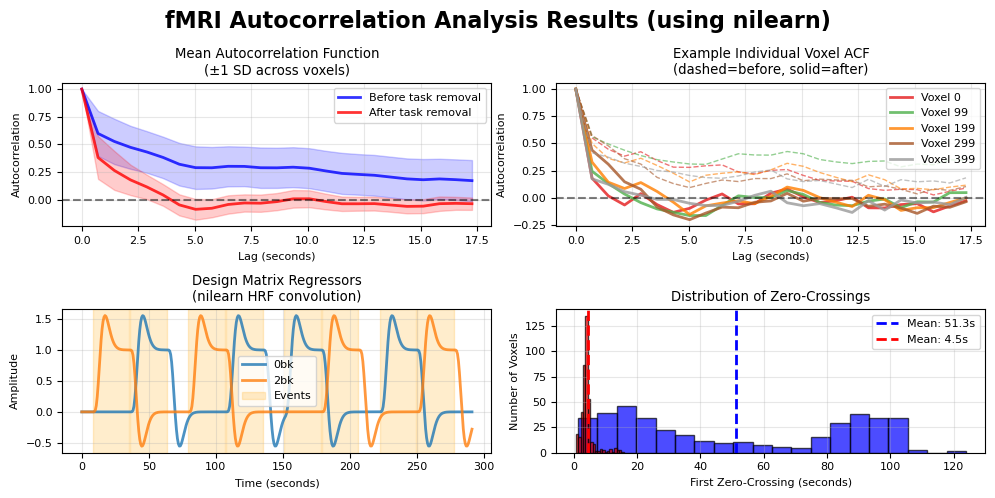

 80%|████████  | 762/947 [00:53<00:11, 15.86it/s]

[Errno 2] No such file or directory: '/mnt/storage_ssd_raid/research_data/HCP_YA/HCP_1200/668361/MNINonLinear/Results/tfMRI_WM_RL/EVs'


100%|██████████| 947/947 [01:06<00:00, 14.24it/s]


1
tfMRI_EMOTION_RL


  0%|          | 0/947 [00:00<?, ?it/s]

['fear' 'neut']


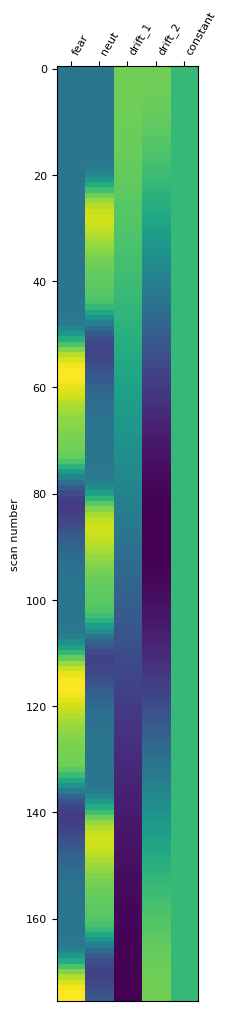

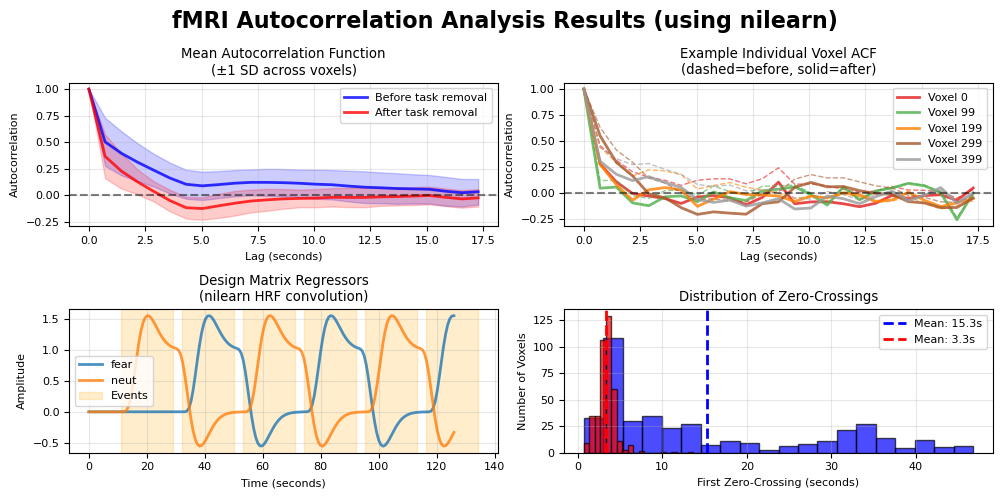

100%|██████████| 947/947 [00:39<00:00, 23.68it/s]


0
tfMRI_GAMBLING_RL


  0%|          | 0/947 [00:00<?, ?it/s]

['loss' 'win']


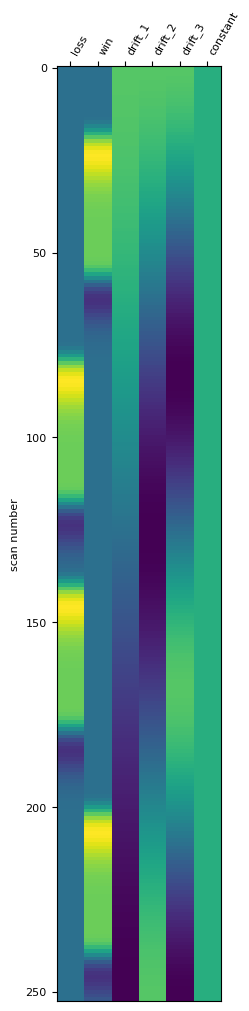

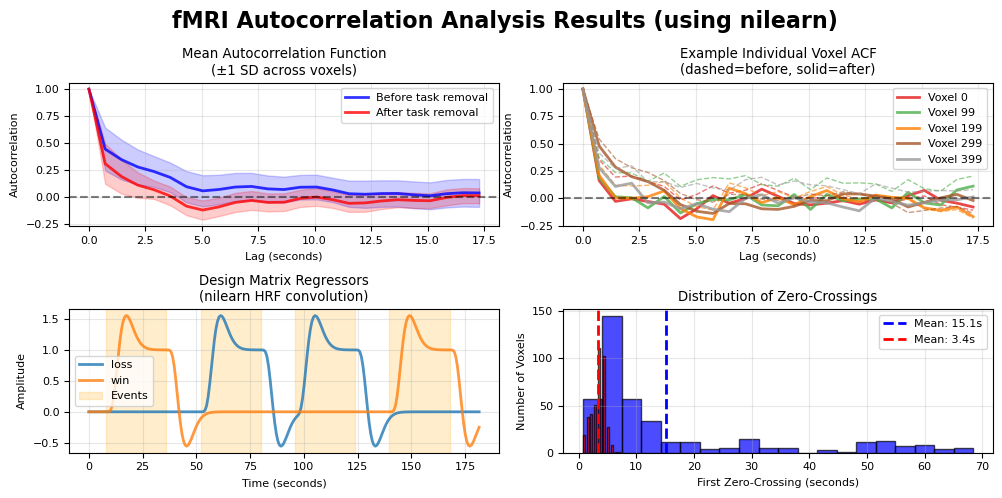

100%|██████████| 947/947 [00:43<00:00, 21.66it/s]


0
tfMRI_LANGUAGE_RL


  0%|          | 0/947 [00:00<?, ?it/s]

['math' 'story']


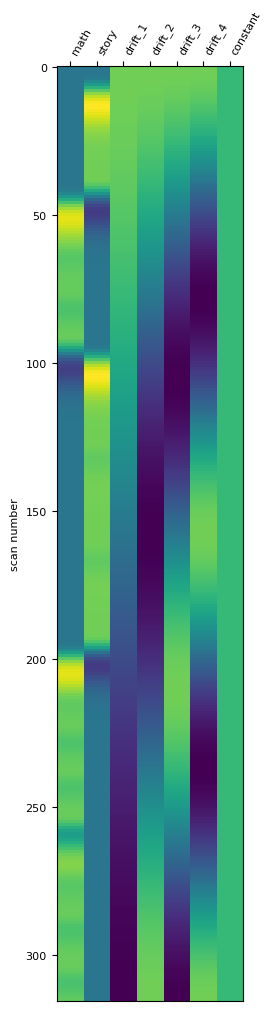

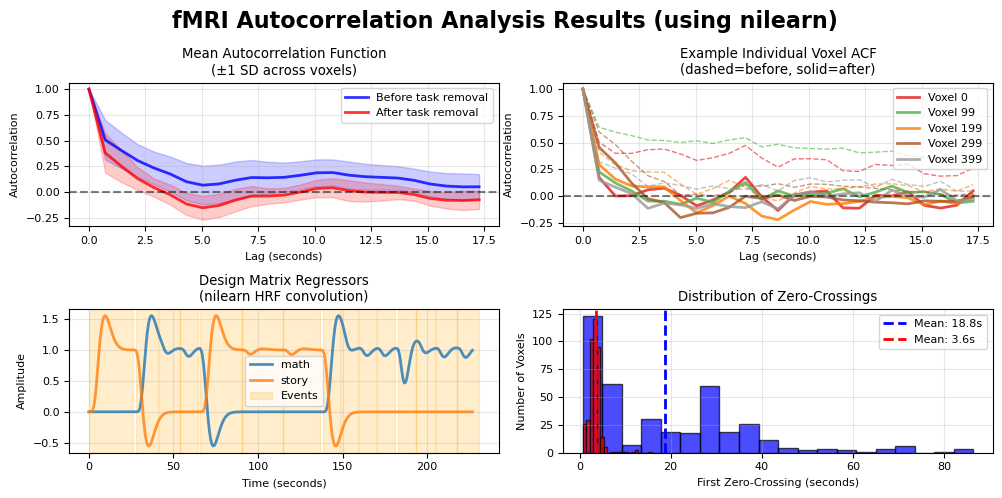

100%|██████████| 947/947 [00:52<00:00, 18.17it/s]


0
tfMRI_RELATIONAL_RL


  0%|          | 0/947 [00:00<?, ?it/s]

['match' 'relation']


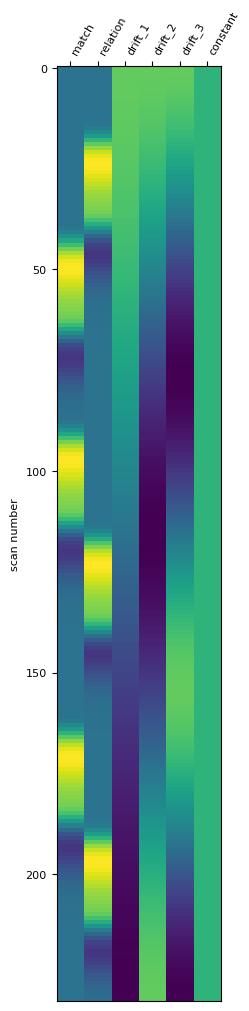

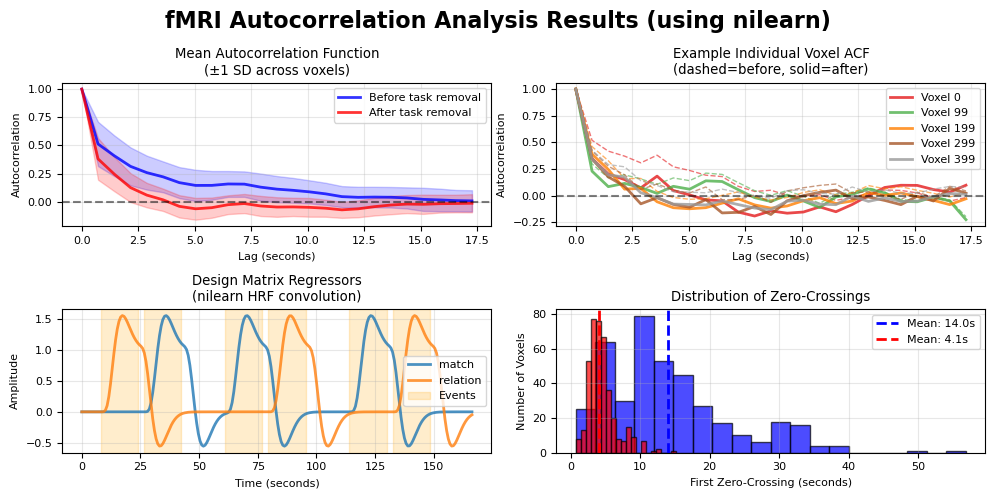

100%|██████████| 947/947 [00:41<00:00, 22.59it/s]


0
tfMRI_SOCIAL_RL


  0%|          | 0/947 [00:00<?, ?it/s]

['mental' 'rnd']


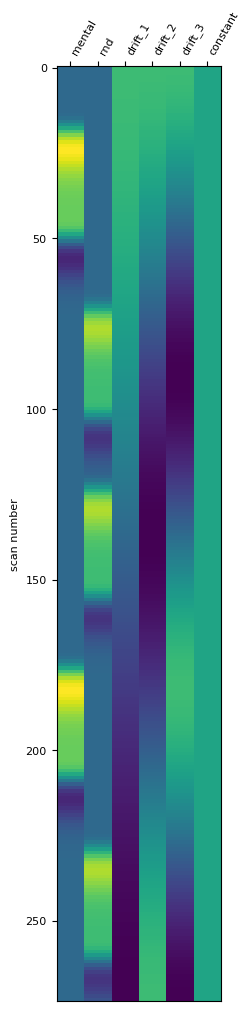

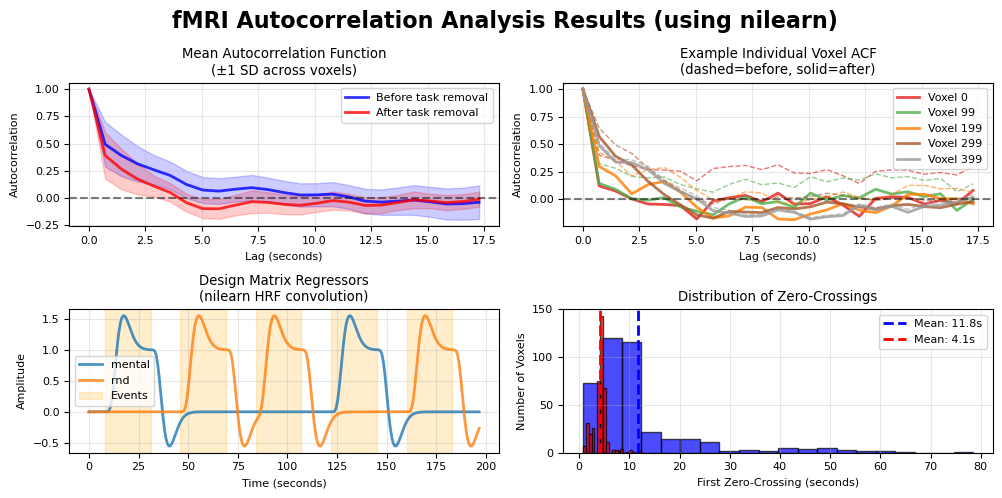

 89%|████████▊ | 839/947 [00:40<00:04, 22.78it/s]

[Errno 2] No such file or directory: '/mnt/storage_ssd_raid/research_data/HCP_YA/HCP_1200/809252/MNINonLinear/Results/tfMRI_SOCIAL_RL/EVs'


100%|██████████| 947/947 [00:45<00:00, 20.88it/s]

1


In [6]:
subject_filter_global = np.zeros(n_subs).astype(bool)
task_timescales = dict()
contrasts = dict()

for which_task in tasks:
    print(which_task)
    if 'tfMRI_WM' in which_task:
        contrasts_list = ['0bk', '2bk']
    elif 'tfMRI_EMOTION' in which_task:
        contrasts_list = ['fear', 'neut']
    elif 'tfMRI_GAMBLING' in which_task:
        contrasts_list = ['win', 'loss']
    elif 'tfMRI_LANGUAGE' in which_task:
        contrasts_list = ['math', 'story']
    elif 'tfMRI_RELATIONAL' in which_task:
        contrasts_list = ['match', 'relation']
    elif 'tfMRI_SOCIAL' in which_task:
        contrasts_list = ['mental', 'rnd']
    elif 'tfMRI_CARIT' in which_task:
        contrasts_list = ['go', 'miss', 'nogoCRLose', 'nogoCRWin', 'nogoFALose', 'nogoFAWin']
        contrasts_list_short = ['go', 'nogo']
    elif 'tfMRI_EMOTION' in which_task:
        contrasts_list = ['faces', 'shapes']
    elif 'tfMRI_GUESSING' in which_task:
        contrasts_list = ['cueHigh', 'cueLow', 'feedbackHighLose', 'feedbackHighWin', 'feedbackLowLose', 'feedbackLowWin', 'guess']
    elif which_task == 'frac2back':
        contrasts_list = ['0back', '1back', '2back']

    subject_filter = np.zeros(n_subs).astype(bool)
    task_ts = np.load(os.path.join(indir, '{0}_{1}_taskts-{2}.npy'.format(which_data.replace('_', ''), atlas, which_task.replace('_', ''))))

    df_task_events_summary = pd.DataFrame(index=subject_ids)
    task_timescales[which_task] = np.zeros((n_subs, n_parcels))
    # task_timescales_alff[which_task] = np.zeros((n_subs, n_parcels))
    if which_task == 'tfMRI_CARIT_PA':
        contrasts[which_task] = dict.fromkeys(contrasts_list_short)
        for contrast in contrasts_list_short:
            contrasts[which_task][contrast] = np.zeros((n_subs, n_parcels))
    else:
        contrasts[which_task] = dict.fromkeys(contrasts_list)
        for contrast in contrasts_list:
            contrasts[which_task][contrast] = np.zeros((n_subs, n_parcels))

    for i in tqdm(np.arange(n_subs)):
        try:
            subjid = subject_ids[i]
            if which_data == 'HCP-YA':
                ev_dir = os.path.join('/mnt/storage_ssd_raid/research_data/HCP_YA/HCP_1200', str(subjid), 'MNINonLinear', 'Results', which_task, 'EVs')
                task_events = get_task_events(ev_dir)
            elif which_data == 'HCP-D':
                subjid_converted = subjid.split('-')[1].replace('V1MR', '_V1_MR')
                ev_dir = os.path.join('/mnt/storage_ssd_raid/research_data/HCP_D/processed', subjid_converted, 'MNINonLinear', 'Results', which_task, 'EVs')
                task_events = get_task_events(ev_dir)
            elif which_data == 'RBC-PNC':
                ev_dir = os.path.join('/mnt/storage_ssd_raid/research_data/RBC/PNC/bids', subjid, 'ses-PNC1', 'func')
                ev_file = os.path.join(ev_dir, '{0}_ses-PNC1_task-frac2back_events.tsv'.format(subjid))
                task_events = pd.read_csv(ev_file, delimiter='\t')

            if which_task == 'tfMRI_CARIT_PA':
                for j in np.arange(task_events.shape[0]):
                    if 'nogo' in task_events.loc[j, 'trial_type']:
                        task_events.loc[j, 'trial_type'] = 'nogo'
                
                retain_idx = task_events['trial_type'] != 'miss'
                task_events = task_events.loc[retain_idx, :]
            elif which_task == 'tfMRI_WM_LR' or which_task == 'tfMRI_WM_RL':
                for j in np.arange(task_events.shape[0]):
                    if '0bk' in task_events.loc[j, 'trial_type']:
                        task_events.loc[j, 'trial_type'] = '0bk'
                    elif '2bk' in task_events.loc[j, 'trial_type']:
                        task_events.loc[j, 'trial_type'] = '2bk'
            # elif which_task == 'frac2back':
                # task_events = task_events[task_events['trial_type'] != 'instr']
                # task_events.reset_index(drop=True, inplace=True)
                
            # unique_events = np.unique(task_events['trial_type'])
            for event in list(contrasts[which_task].keys()):
                df_task_events_summary.loc[subjid, event] = np.sum(task_events['trial_type'] == event)

            fmri_data = task_ts[:, :, i].T
            autocorr_raw, zero_crossings_raw, autocorr_resid, zero_crossings_resid, residuals, design_matrix = compute_autocorrelation_with_hrf(fmri_data, task_events, tr, 
                                                                                                                                                hrf_model='glover', drift_model='cosine')
            task_timescales[which_task][i, :] = zero_crossings_resid
            
            # compute contrasts    
            beta = np.dot(np.linalg.pinv(design_matrix.values), fmri_data.T)
            for contrast in list(contrasts[which_task].keys()):
                contrast_idx = list(design_matrix.columns).index(contrast)
                contrasts[which_task][contrast][i, :] = beta[contrast_idx, :]
                
            if i == 0:
                print(np.unique(task_events['trial_type']))
                plot_design_matrix(design_matrix)
                plot_autocorrelation_analysis(autocorr_raw, autocorr_resid, zero_crossings_raw, zero_crossings_resid, design_matrix, task_events, tr)
                plt.show()
        except Exception as e:
            subject_filter[i] = True
            print(e)
    print(np.sum(subject_filter))
    subject_filter_global += subject_filter

    for contrast in list(contrasts[which_task].keys()):
        contrasts[which_task][contrast] = np.asarray(contrasts[which_task][contrast])

## Save out

In [7]:
np.any(subject_filter_global)

True

In [8]:
if np.any(subject_filter_global):
    subject_ids_filt = subject_ids[~subject_filter_global]
    print(subject_ids_filt.shape)

    for which_scan in rest_timescales.keys():
        rest_timescales[which_scan] = rest_timescales[which_scan][~subject_filter_global, :]
        print(rest_timescales[which_scan].shape)

    for which_task in task_timescales.keys():
        task_timescales[which_task] = task_timescales[which_task][~subject_filter_global, :]
        print(task_timescales[which_task].shape)
        
    for which_task in contrasts.keys():
        for contrast in contrasts[which_task].keys():
            contrasts[which_task][contrast] = contrasts[which_task][contrast][~subject_filter_global, :]
            print(contrasts[which_task][contrast].shape)
            
    np.savetxt(os.path.join(outdir, '{0}_{1}_subjids.txt'.format(which_data, atlas)), subject_ids_filt, fmt='%s')

(945,)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)
(945, 400)


In [9]:
for which_scan in rest_timescales.keys():
    np.save(os.path.join(outdir, '{0}_{1}_{2}_timescales_acflag.npy'.format(which_data, atlas, which_scan.replace('_', ''))), rest_timescales[which_scan])

for which_scan in task_timescales.keys():
    np.save(os.path.join(outdir, '{0}_{1}_{2}_timescales_acflag.npy'.format(which_data, atlas, which_scan.replace('_', ''))), task_timescales[which_scan])

    with open(os.path.join(outdir, '{0}_{1}_{2}_contrasts.pkl'.format(which_data, atlas, which_scan.replace('_', ''))), 'wb') as f:
        pickle.dump(contrasts[which_scan], f)